# Notebook 04 — Temporal Evaluation

**Project:** Temporal Vision / HMDB51 subset  
**Purpose:** Controlled evaluation of how the number, order, and quality of frame observations affect action classification.

This notebook reuses the frozen CLIP/SigLIP frame embeddings, the exact video-level split from Notebook 03, and the best-validation checkpoints trained in Notebook 03. It does **not** retrain the models or regenerate embeddings.

## Controlled experiments implemented

1. **Progressive observation:** evaluate 1, 2, …, N observations. Frames are sampled uniformly across the complete video timeline, rather than taking only the first few frames. The single-frame baseline is reported as a fixed reference.
2. **Temporal order:** compare chronological order, reversed order, and 20 independently shuffled orders using the same trained weights. Report mean and standard deviation across permutations.
3. **Observation corruption:** compare clean inputs against frame dropping, feature masking, and additive Gaussian feature noise at multiple severities. The single-frame baseline receives the corresponding corruption on its selected middle-frame representation.

The assignment asks for at least two controlled experiments; this notebook implements all three.

**Important scope:** The models consume precomputed visual embeddings, not raw pixels. Therefore blur and pixel-level partial occlusion cannot be faithfully simulated here. The corruption experiment uses embedding-space masking/noise and dropped observations, and labels these precisely rather than calling them image blur.

**Fairness:** all experiments use the same held-out test videos and the saved Notebook 03 split. No model is trained on test data. Results are written to a new project-root folder: `Temporal-Evaluation/`.


## 1. Imports, reproducibility and device

In [2]:
import json, time, random, platform, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)


Python: 3.11.15
PyTorch: 2.15.0
Device: mps


## 2. Project paths and output layout

Update `PROJECT_ROOT` only if the project has moved. The notebook expects the same embedding stores and `Single-multiframe` outputs produced by Notebook 03.

In [3]:
PROJECT_ROOT = Path("/Users/vanshikaarora/Desktop/Tracking")
if not PROJECT_ROOT.exists():
    candidate = Path.cwd()
    if (candidate / "embeddings").exists() and (candidate / "Single-multiframe").exists():
        PROJECT_ROOT = candidate
    else:
        raise FileNotFoundError(
            "Project root not found. Set PROJECT_ROOT to the folder containing "
            "'embeddings/' and 'Single-multiframe/'."
        )

EMBEDDINGS_ROOT = PROJECT_ROOT / "embeddings" / "embedding-store"
STAGE4_ROOT = PROJECT_ROOT / "Single-multiframe"
OUTPUT_ROOT = PROJECT_ROOT / "Temporal-Evaluation"

PROGRESSIVE_ROOT = OUTPUT_ROOT / "Progressive_Observation"
ORDER_ROOT = OUTPUT_ROOT / "Temporal_Order"
CORRUPTION_ROOT = OUTPUT_ROOT / "Observation_Corruption"
SUMMARY_ROOT = OUTPUT_ROOT / "Summary"

for p in [OUTPUT_ROOT, PROGRESSIVE_ROOT, ORDER_ROOT, CORRUPTION_ROOT, SUMMARY_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

ENCODERS = {"clip": 512, "siglip": 768}
TEMPORAL_MODELS = ["GRU", "LSTM", "Transformer_Encoder", "Temporal_CNN"]
ALL_MODELS = ["SingleFrame", "MeanPooling"] + TEMPORAL_MODELS

print("Project:", PROJECT_ROOT)
print("Stage 4:", STAGE4_ROOT)
print("Stage 5 output:", OUTPUT_ROOT)


Project: /Users/vanshikaarora/Desktop/Tracking
Stage 4: /Users/vanshikaarora/Desktop/Tracking/Single-multiframe
Stage 5 output: /Users/vanshikaarora/Desktop/Tracking/Temporal-Evaluation


## 3. Load the saved video split and embedding stores

The split CSV from Notebook 03 is authoritative. We deliberately do not create a new split, because that would make stage-to-stage comparisons less direct.

In [4]:
split_path = STAGE4_ROOT / "data-splits" / "video_level_splits.csv"
if not split_path.exists():
    raise FileNotFoundError(f"Missing saved split: {split_path}. Run Notebook 03 first.")

split_df = pd.read_csv(split_path, dtype={"video_id": str})
required_split_cols = {"video_id", "label", "split"}
if not required_split_cols.issubset(split_df.columns):
    raise ValueError(f"Split CSV must contain {required_split_cols}; found {split_df.columns.tolist()}")

if split_df["video_id"].duplicated().any():
    raise ValueError("A video appears more than once in the saved split file.")

SPLITS = {s: set(split_df.loc[split_df["split"] == s, "video_id"].astype(str))
          for s in ["train", "validation", "test"]}
assert not (SPLITS["train"] & SPLITS["validation"])
assert not (SPLITS["train"] & SPLITS["test"])
assert not (SPLITS["validation"] & SPLITS["test"])
TEST_IDS = SPLITS["test"]

LABELS = sorted(split_df["label"].astype(str).unique().tolist())
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
ID_TO_LABEL = {i: name for name, i in LABEL_TO_ID.items()}
NUM_CLASSES = len(LABELS)

print("Split sizes:", {k: len(v) for k, v in SPLITS.items()})
print("Classes:", LABELS)


Split sizes: {'train': 664, 'validation': 143, 'test': 143}
Classes: ['brush_hair', 'cartwheel', 'catch', 'chew', 'clap', 'climb', 'climb_stairs', 'dive', 'draw_sword']


## 4. Resolve manifest columns and build ordered video sequences

Each record contains the video ID, label, frame indices and ordered feature sequence. We verify that CLIP and SigLIP describe the same videos and frame order.

In [5]:
COLUMN_CANDIDATES = {
    "video_id": ["video_id", "video", "sequence_id", "video_name", "filename", "video_path"],
    "label": ["label", "class", "class_name", "action", "category"],
    "frame_index": ["frame_index", "frame_idx", "frame_number", "frame_id", "index"],
}
COLUMN_OVERRIDES = {"video_id": None, "label": None, "frame_index": None}

def resolve_column(df, key):
    if COLUMN_OVERRIDES[key] is not None:
        col = COLUMN_OVERRIDES[key]
        if col not in df.columns:
            raise KeyError(f"Override column {col!r} missing.")
        return col
    for col in COLUMN_CANDIDATES[key]:
        if col in df.columns:
            return col
    raise KeyError(f"Cannot resolve {key}; columns={df.columns.tolist()}")

def load_records(encoder, expected_dim):
    store = EMBEDDINGS_ROOT / encoder
    emb_path, manifest_path = store / "frame_embeddings.npy", store / "frame_manifest.csv"
    for p in [emb_path, manifest_path, store / "embedding_metadata.json"]:
        if not p.exists():
            raise FileNotFoundError(f"Missing embedding artifact: {p}")
    embeddings = np.load(emb_path, mmap_mode="r")
    manifest = pd.read_csv(manifest_path)
    if embeddings.ndim != 2 or embeddings.shape[1] != expected_dim:
        raise ValueError(f"{encoder}: unexpected embedding shape {embeddings.shape}")
    if len(manifest) != len(embeddings):
        raise ValueError(f"{encoder}: manifest/embedding row count mismatch")

    vc, lc, fc = [resolve_column(manifest, k) for k in ["video_id", "label", "frame_index"]]
    manifest = manifest.copy()
    manifest["_vid"] = manifest[vc].astype(str)
    manifest["_label"] = manifest[lc].astype(str)
    manifest["_frame"] = pd.to_numeric(manifest[fc], errors="coerce")
    manifest["_row"] = np.arange(len(manifest))
    if manifest["_frame"].isna().any():
        raise ValueError(f"{encoder}: non-numeric frame indices")

    records = []
    for vid, group in manifest.groupby("_vid", sort=True):
        group = group.sort_values("_frame", kind="stable")
        labels = group["_label"].unique()
        if len(labels) != 1:
            raise ValueError(f"{encoder}: inconsistent labels for {vid}")
        if group["_frame"].duplicated().any():
            raise ValueError(f"{encoder}: duplicate frame indices for {vid}")
        seq = np.asarray(embeddings[group["_row"].to_numpy()], dtype=np.float32)
        if len(seq) < 2 or not np.isfinite(seq).all():
            raise ValueError(f"{encoder}: invalid sequence for {vid}")
        records.append({
            "video_id": str(vid), "label": str(labels[0]),
            "frame_indices": group["_frame"].to_numpy(dtype=int),
            "sequence": seq,
        })
    return records

VIDEO_RECORDS = {e: load_records(e, d) for e, d in ENCODERS.items()}

def signatures(records):
    return {r["video_id"]: (r["label"], tuple(r["frame_indices"])) for r in records}

if signatures(VIDEO_RECORDS["clip"]) != signatures(VIDEO_RECORDS["siglip"]):
    raise ValueError("CLIP and SigLIP video/frame manifests differ.")

for encoder, records in VIDEO_RECORDS.items():
    ids = {r["video_id"] for r in records}
    if ids != set.union(*SPLITS.values()):
        raise ValueError(f"{encoder}: embedding videos do not match the saved split IDs.")
    print(encoder, "videos:", len(records), "frame lengths:",
          pd.Series([len(r["sequence"]) for r in records]).value_counts().sort_index().to_dict())

TEST_RECORDS = {
    enc: [r for r in records if r["video_id"] in TEST_IDS]
    for enc, records in VIDEO_RECORDS.items()
}
assert len(TEST_RECORDS["clip"]) == len(TEST_RECORDS["siglip"])
print("Held-out test videos:", len(TEST_RECORDS["clip"]))


clip videos: 950 frame lengths: {7: 938, 8: 12}
siglip videos: 950 frame lengths: {7: 938, 8: 12}
Held-out test videos: 143


## 5. Recreate the exact Notebook 03 model architectures and load best checkpoints

Only the saved best-validation checkpoints are loaded. This section mirrors the model definitions and checkpoint paths from Notebook 03. If a checkpoint is missing or its label mapping differs, execution stops rather than silently substituting another model.

In [6]:
DROPOUT = 0.25

class MLPClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(128, num_classes),
        )
    def forward(self, x, lengths=None):
        return self.net(x)

class RecurrentClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, cell="GRU"):
        super().__init__()
        rnn_cls = nn.GRU if cell.upper() == "GRU" else nn.LSTM
        self.input_proj = nn.Linear(input_dim, 128)
        self.rnn = rnn_cls(128, 128, num_layers=1, batch_first=True,
                           dropout=0.0, bidirectional=False)
        self.head = nn.Sequential(
            nn.Dropout(DROPOUT), nn.Linear(128, 64), nn.ReLU(),
            nn.Dropout(DROPOUT), nn.Linear(64, num_classes),
        )
    def forward(self, x, lengths):
        x = self.input_proj(x)
        packed = nn.utils.rnn.pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)
        if isinstance(hidden, tuple):
            hidden = hidden[0]
        return self.head(hidden[-1])

class TransformerClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, max_frames=32):
        super().__init__()
        self.proj = nn.Linear(input_dim, 128)
        self.pos_embedding = nn.Parameter(torch.randn(1, max_frames, 128) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=128, nhead=4, dim_feedforward=256, dropout=DROPOUT,
            batch_first=True, norm_first=True, activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.norm = nn.LayerNorm(128)
        self.head = nn.Sequential(
            nn.Linear(128, 64), nn.GELU(), nn.Dropout(DROPOUT),
            nn.Linear(64, num_classes)
        )
    def forward(self, x, lengths):
        b, t, _ = x.shape
        if t > self.pos_embedding.shape[1]:
            raise ValueError("Sequence longer than positional embedding capacity.")
        mask = torch.arange(t, device=x.device)[None, :] >= lengths.to(x.device)[:, None]
        x = self.proj(x) + self.pos_embedding[:, :t]
        x = self.encoder(x, src_key_padding_mask=mask)
        x = self.norm(x)
        valid = (~mask).unsqueeze(-1).to(x.dtype)
        pooled = (x * valid).sum(1) / lengths.to(x.device).unsqueeze(1)
        return self.head(pooled)

class TemporalResidualBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, 3, padding=dilation, dilation=dilation)
        self.conv2 = nn.Conv1d(channels, channels, 3, padding=dilation, dilation=dilation)
        self.norm1 = nn.BatchNorm1d(channels)
        self.norm2 = nn.BatchNorm1d(channels)
        self.act = nn.GELU()
        self.drop = nn.Dropout(DROPOUT)
    def forward(self, x):
        residual = x
        x = self.drop(self.act(self.norm1(self.conv1(x))))
        x = self.drop(self.norm2(self.conv2(x)))
        return self.act(x + residual)

class TemporalCNNClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.input_proj = nn.Conv1d(input_dim, 128, kernel_size=1)
        self.blocks = nn.Sequential(
            TemporalResidualBlock(128, 1), TemporalResidualBlock(128, 2)
        )
        self.head = nn.Sequential(
            nn.Linear(128, 64), nn.GELU(), nn.Dropout(DROPOUT),
            nn.Linear(64, num_classes)
        )
    def forward(self, x, lengths):
        x = self.input_proj(x.transpose(1, 2))
        x = self.blocks(x)
        valid = (torch.arange(x.shape[-1], device=x.device)[None, :]
                 < lengths.to(x.device)[:, None]).unsqueeze(1).to(x.dtype)
        pooled = (x * valid).sum(-1) / lengths.to(x.device).unsqueeze(1)
        return self.head(pooled)

def build_model(model_name, input_dim):
    if model_name in ["SingleFrame", "MeanPooling"]:
        return MLPClassifier(input_dim, NUM_CLASSES)
    if model_name == "GRU":
        return RecurrentClassifier(input_dim, NUM_CLASSES, "GRU")
    if model_name == "LSTM":
        return RecurrentClassifier(input_dim, NUM_CLASSES, "LSTM")
    if model_name == "Transformer_Encoder":
        return TransformerClassifier(input_dim, NUM_CLASSES)
    if model_name == "Temporal_CNN":
        return TemporalCNNClassifier(input_dim, NUM_CLASSES)
    raise ValueError(model_name)

def checkpoint_dir(encoder, model):
    if model == "SingleFrame":
        return STAGE4_ROOT / "Baseline" / encoder / "SingleFrame"
    if model == "MeanPooling":
        return STAGE4_ROOT / "Baseline" / encoder / "MeanPooling_Control"
    return STAGE4_ROOT / "Temporal" / model / encoder

MODELS = {}
CHECKPOINT_METADATA = []
for encoder, dim in ENCODERS.items():
    for model_name in ALL_MODELS:
        ckpt_path = checkpoint_dir(encoder, model_name) / "best_model.pt"
        if not ckpt_path.exists():
            raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}. Run Notebook 03 fully.")
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except TypeError:
            ckpt = torch.load(ckpt_path, map_location="cpu")
        if ckpt.get("label_to_id") != LABEL_TO_ID:
            raise ValueError(f"Label mapping mismatch in {ckpt_path}")
        model = build_model(model_name, dim)
        model.load_state_dict(ckpt["model_state_dict"], strict=True)
        model.to(DEVICE).eval()
        MODELS[(encoder, model_name)] = model
        CHECKPOINT_METADATA.append({
            "encoder": encoder, "model": model_name,
            "checkpoint": str(ckpt_path),
            "best_epoch": ckpt.get("best_epoch"),
            "best_validation_macro_f1": ckpt.get("best_validation_macro_f1"),
        })

pd.DataFrame(CHECKPOINT_METADATA).to_csv(OUTPUT_ROOT / "loaded_checkpoint_manifest.csv", index=False)
print("Loaded", len(MODELS), "checkpoints.")


Loaded 12 checkpoints.


/var/folders/yk/975v12617wjby1k2n4krpjp00000gn/T/ipykernel_62836/1904148596.py:44: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=2)


## 6. Shared inference and metric utilities

The test videos are evaluated one at a time so that each experiment can modify only valid observations without introducing padding artifacts. All model outputs are computed in evaluation mode.

In [7]:
def predict_one(model, model_name, sequence):
    # sequence is a float32 NumPy array with shape [T, D].
    x = torch.as_tensor(sequence, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    length = torch.tensor([len(sequence)], dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        if model_name == "SingleFrame" or model_name == "MeanPooling":
            if model_name == "SingleFrame":
                features = x[:, (len(sequence) - 1) // 2, :]
            else:
                features = x.mean(dim=1)
            logits = model(features)
        else:
            logits = model(x, length)
        probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    return probs

def summarize_predictions(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        average="macro", zero_division=0
    )
    wf1 = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )[2]
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(p), "macro_recall": float(r),
        "macro_f1": float(f1), "weighted_f1": float(wf1),
    }

def evaluate_records(encoder, model_name, records, sequence_transform=None):
    ys, preds, probs_rows, ids = [], [], [], []
    model = MODELS[(encoder, model_name)]
    for rec in records:
        seq = rec["sequence"]
        if sequence_transform is not None:
            seq = sequence_transform(rec, seq)
        probs = predict_one(model, model_name, seq)
        ys.append(LABEL_TO_ID[rec["label"]])
        preds.append(int(np.argmax(probs)))
        probs_rows.append(probs)
        ids.append(rec["video_id"])
    metrics = summarize_predictions(np.asarray(ys), np.asarray(preds))
    return metrics, np.asarray(ys), np.asarray(preds), np.asarray(probs_rows), ids

def save_predictions(path, ids, ys, preds, probs=None):
    df = pd.DataFrame({
        "video_id": ids,
        "y_true_id": ys,
        "y_true": [ID_TO_LABEL[int(x)] for x in ys],
        "y_pred_id": preds,
        "y_pred": [ID_TO_LABEL[int(x)] for x in preds],
        "correct": ys == preds,
    })
    if probs is not None:
        df["max_probability"] = probs.max(axis=1)
    df.to_csv(path, index=False)
    return df

def plot_metric(df, x, y, hue, title, path, ylabel="Macro-F1"):
    fig, ax = plt.subplots(figsize=(11, 5))
    for key, part in df.groupby(hue):
        part = part.sort_values(x)
        ax.plot(part[x], part[y], marker="o", label=str(key))
    ax.set_title(title)
    ax.set_xlabel(x.replace("_", " ").title())
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Experiment A — Progressive Observation

## 7. Evaluate 1, 2, …, N observations

For each video and each requested observation count `k`, select `k` frame embeddings uniformly across the full timeline. For `k=1`, the middle frame is selected, matching the deterministic single-frame baseline's frame choice. The learned temporal models are evaluated with these reduced sequences **without retraining**.

We report:
- the single-frame checkpoint as a constant reference;
- the mean-pooling checkpoint as an order-agnostic multi-observation control;
- all four temporal checkpoints at each observation count.

Because the models were trained on full sequences, reduced-observation inference is a controlled robustness/observation-budget test, not a separately optimized `k`-frame model.

Progressive observation budgets: [1, 2, 3, 4, 5, 6, 7]
Videos in every point: 143


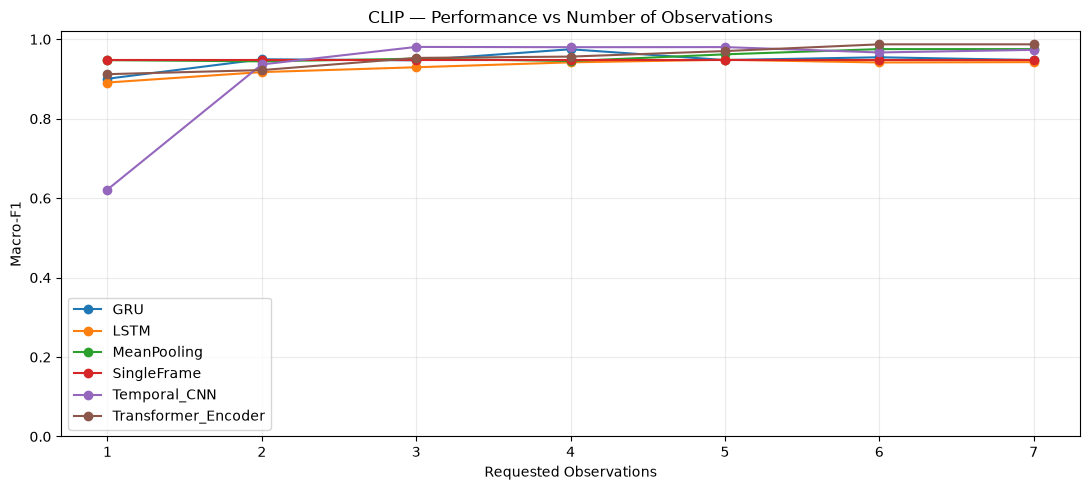

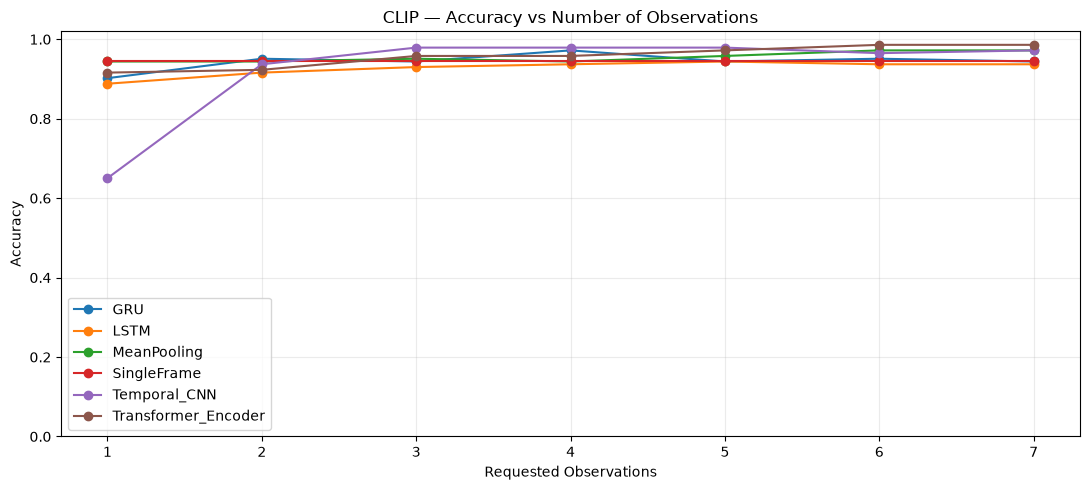

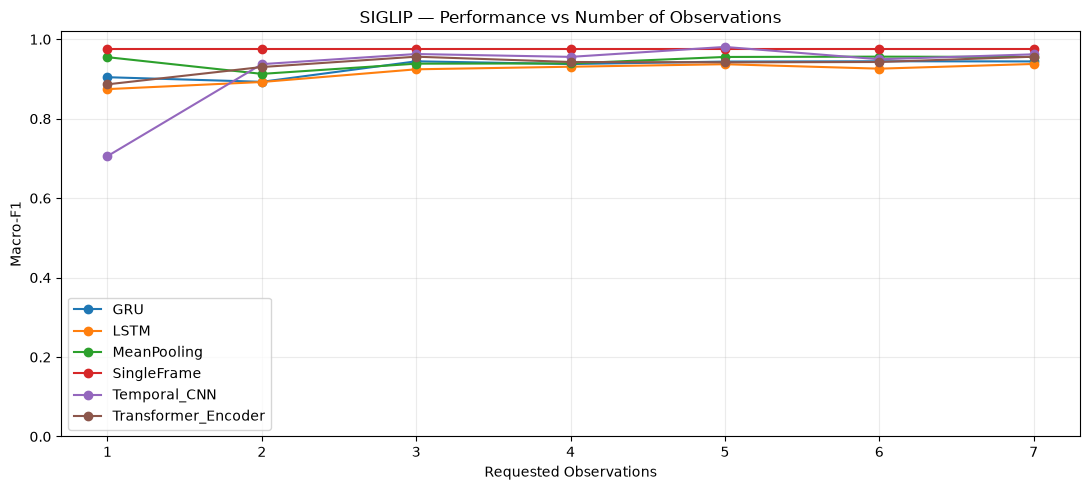

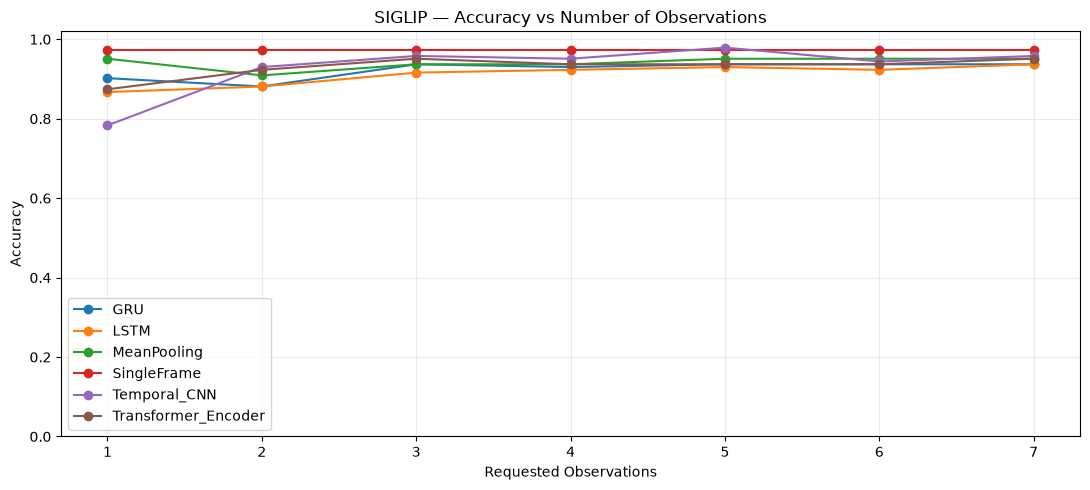

,encoder,model,requested_observations,mean_actual_observations,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
2,clip,GRU,1,1.0,0.902098,0.897450,0.911221,0.900685,0.902005
8,clip,GRU,2,2.0,0.951049,0.952436,0.951688,0.949657,0.951128
14,clip,GRU,3,3.0,0.944056,0.950613,0.945207,0.946997,0.943864
20,clip,GRU,4,4.0,0.972028,0.978313,0.973557,0.974871,0.972472
26,clip,GRU,5,5.0,0.944056,0.950998,0.946187,0.947723,0.944266
...,...,...,...,...,...,...,...,...,...
58,siglip,Transformer_Encoder,3,3.0,0.951049,0.963684,0.954112,0.956136,0.952115
64,siglip,Transformer_Encoder,4,4.0,0.937063,0.952976,0.939760,0.942826,0.938308
70,siglip,Transformer_Encoder,5,5.0,0.937063,0.948853,0.939760,0.941905,0.937334
76,siglip,Transformer_Encoder,6,6.0,0.937063,0.951626,0.939760,0.942814,0.937785


In [8]:
def uniform_indices(n_frames, k):
    if k < 1 or k > n_frames:
        raise ValueError(f"k must be in [1, {n_frames}]")
    if k == 1:
        return np.array([(n_frames - 1) // 2], dtype=int)
    return np.unique(np.rint(np.linspace(0, n_frames - 1, k)).astype(int))

def select_uniform_observations(record, sequence, k):
    idx = uniform_indices(len(sequence), k)
    return sequence[idx]

# Use the largest observation budget available for EVERY test video.
# In this dataset, all test videos have at least 7 frames, while only a few
# have 8. Setting N=7 keeps the test population and observation count fixed.
max_frames = min(len(r["sequence"]) for r in TEST_RECORDS["clip"])
print("Progressive observation budgets:", list(range(1, max_frames + 1)))
print("Videos in every point:", len(TEST_RECORDS["clip"]))

progressive_rows = []
progressive_predictions = []

for encoder, records in TEST_RECORDS.items():
    for k in range(1, max_frames + 1):
        for model_name in ALL_MODELS:
            ys, preds, ids, actual_counts = [], [], [], []
            model = MODELS[(encoder, model_name)]
            for rec in records:
                if model_name == "SingleFrame":
                    # Fixed single-frame baseline: ALWAYS use the original
                    # video's middle frame, regardless of the requested k.
                    middle = (len(rec["sequence"]) - 1) // 2
                    seq = rec["sequence"][middle:middle + 1]
                else:
                    # Temporal and mean-pooling models receive k observations
                    # sampled uniformly across the full video timeline.
                    seq = select_uniform_observations(rec, rec["sequence"], k)

                probs = predict_one(model, model_name, seq)
                ys.append(LABEL_TO_ID[rec["label"]])
                preds.append(int(probs.argmax()))
                ids.append(rec["video_id"])
                actual_counts.append(len(seq))

            metrics = summarize_predictions(np.asarray(ys), np.asarray(preds))
            progressive_rows.append({
                "encoder": encoder, "model": model_name,
                "requested_observations": k,
                "mean_actual_observations": float(np.mean(actual_counts)),
                **metrics,
            })
            if k in [1, max_frames]:
                for vid, y, pred, count in zip(ids, ys, preds, actual_counts):
                    progressive_predictions.append({
                        "encoder": encoder, "model": model_name,
                        "requested_observations": k, "video_id": vid,
                        "y_true_id": y, "y_pred_id": pred,
                        "correct": y == pred, "actual_observations": count,
                    })

progressive_df = pd.DataFrame(progressive_rows)
progressive_df.to_csv(PROGRESSIVE_ROOT / "progressive_observation_metrics.csv", index=False)
pd.DataFrame(progressive_predictions).to_csv(
    PROGRESSIVE_ROOT / "progressive_observation_endpoint_predictions.csv", index=False
)

for encoder in ENCODERS:
    subset = progressive_df[progressive_df["encoder"] == encoder]
    plot_metric(
        subset, "requested_observations", "macro_f1", "model",
        f"{encoder.upper()} — Performance vs Number of Observations",
        PROGRESSIVE_ROOT / f"{encoder}_progressive_macro_f1.png"
    )
    plot_metric(
        subset, "requested_observations", "accuracy", "model",
        f"{encoder.upper()} — Accuracy vs Number of Observations",
        PROGRESSIVE_ROOT / f"{encoder}_progressive_accuracy.png",
        ylabel="Accuracy"
    )

display(progressive_df.sort_values(["encoder", "model", "requested_observations"]))


# Experiment B — Temporal Order

## 9. Chronological vs reversed vs repeatedly shuffled sequences

For each temporal checkpoint, evaluate:
- chronological frame order;
- reversed frame order;
- 20 independent random permutations of each video's valid frames.

The same trained weights and the same test videos are used throughout. We report the mean and standard deviation of macro-F1 across random permutations. This is more informative than relying on one shuffled ordering.

Single-frame and mean-pooling models are order-invariant by construction and are not included in this order-sensitivity experiment.

In [10]:
N_SHUFFLE_REPEATS = 20
order_rows = []
order_prediction_rows = []

for encoder, records in TEST_RECORDS.items():
    for model_name in TEMPORAL_MODELS:
        model = MODELS[(encoder, model_name)]
        # Correct chronological order
        clean_metrics, y_true, y_pred, probs, ids = evaluate_records(
            encoder, model_name, records
        )
        order_rows.append({
            "encoder": encoder, "model": model_name, "condition": "chronological",
            "repeat": 0, **clean_metrics
        })
        save_predictions(
            ORDER_ROOT / f"{encoder}_{model_name}_chronological_predictions.csv",
            ids, y_true, y_pred, probs
        )

        # Reverse the valid sequence
        reverse_metrics, ry, rp, rprobs, rids = evaluate_records(
            encoder, model_name, records,
            sequence_transform=lambda rec, seq: seq[::-1].copy()
        )
        order_rows.append({
            "encoder": encoder, "model": model_name, "condition": "reversed",
            "repeat": 0, **reverse_metrics
        })
        save_predictions(
            ORDER_ROOT / f"{encoder}_{model_name}_reversed_predictions.csv",
            rids, ry, rp, rprobs
        )

        # Repeat independent permutations; deterministic seeds are saved.
        for repeat in range(N_SHUFFLE_REPEATS):
            rng = np.random.default_rng(SEED + 1000 * (repeat + 1) + (0 if encoder == "clip" else 50000))
            def shuffle_transform(rec, seq, _rng=rng):
                return seq[_rng.permutation(len(seq))]
            sh_metrics, sy, sp, sprob, sids = evaluate_records(
                encoder, model_name, records, sequence_transform=shuffle_transform
            )
            order_rows.append({
                "encoder": encoder, "model": model_name,
                "condition": "shuffled", "repeat": repeat + 1,
                "shuffle_seed": SEED + 1000 * (repeat + 1) + (0 if encoder == "clip" else 50000),
                **sh_metrics
            })

order_df = pd.DataFrame(order_rows)
order_df.to_csv(ORDER_ROOT / "temporal_order_all_repeats.csv", index=False)

order_summary = (
    order_df.groupby(["encoder", "model", "condition"])
    .agg(
        accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
        weighted_f1_mean=("weighted_f1", "mean"),
        repeats=("repeat", "count")
    ).reset_index()
)
order_summary.to_csv(ORDER_ROOT / "temporal_order_summary.csv", index=False)
display(order_summary)


,encoder,model,condition,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,repeats
0,clip,GRU,chronological,0.944056,NaN,0.947762,NaN,0.944280,1
1,clip,GRU,reversed,0.930070,NaN,0.935377,NaN,0.930546,1
2,clip,GRU,shuffled,0.940210,0.005773,0.944407,0.005351,0.940536,20
3,clip,LSTM,chronological,0.937063,NaN,0.942489,NaN,0.936622,1
4,clip,LSTM,reversed,0.958042,NaN,0.961176,NaN,0.957959,1
5,clip,LSTM,shuffled,0.950350,0.006377,0.954689,0.005785,0.950149,20
6,clip,Temporal_CNN,chronological,0.972028,NaN,0.973347,NaN,0.971970,1
7,clip,Temporal_CNN,reversed,0.972028,NaN,0.973347,NaN,0.971970,1
8,clip,Temporal_CNN,shuffled,0.974126,0.003995,0.975461,0.003973,0.974072,20
9,clip,Transformer_Encoder,chronological,0.986014,NaN,0.987273,NaN,0.985963,1


## 10. Temporal order plots and order sensitivity

`chronological − shuffled mean` and `chronological − reversed` are descriptive differences in macro-F1. Positive values indicate that the altered order hurt performance. Negative values mean the altered order performed better. A small difference suggests limited dependence on exact order in this evaluation.

condition,encoder,model,chronological,reversed,shuffled,chronological_minus_shuffled_pp,chronological_minus_reversed_pp
0,clip,GRU,0.947762,0.935377,0.944407,0.335492,1.238486
1,clip,LSTM,0.942489,0.961176,0.954689,-1.219981,-1.868673
2,clip,Temporal_CNN,0.973347,0.973347,0.975461,-0.211432,0.000000
3,clip,Transformer_Encoder,0.987273,0.981099,0.980487,0.678505,0.617355
4,siglip,GRU,0.944254,0.955698,0.959658,-1.540375,-1.144329
5,siglip,LSTM,0.937864,0.936098,0.933535,0.432885,0.176535
6,siglip,Temporal_CNN,0.962140,0.962140,0.958300,0.384041,0.000000
7,siglip,Transformer_Encoder,0.956124,0.949567,0.953432,0.269146,0.655702


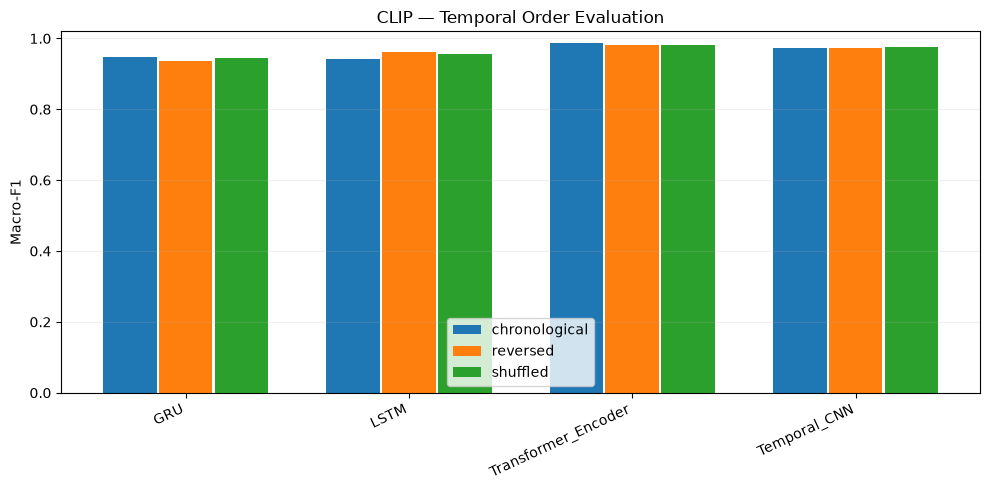

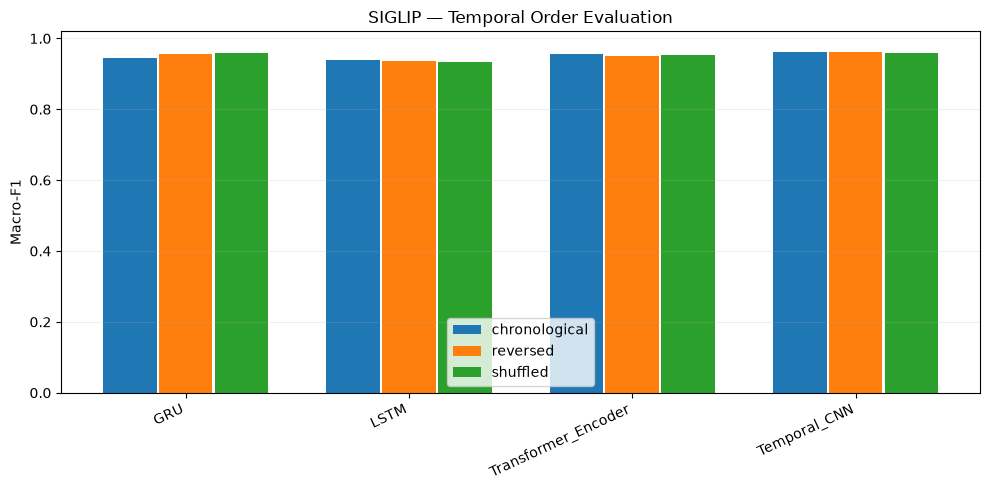

In [ ]:
order_pivot = order_summary.pivot_table(
    index=["encoder", "model"], columns="condition", values="macro_f1_mean"
).reset_index()
order_pivot["chronological_minus_shuffled_pp"] = (
    order_pivot["chronological"] - order_pivot["shuffled"]
) * 100
order_pivot["chronological_minus_reversed_pp"] = (
    order_pivot["chronological"] - order_pivot["reversed"]
) * 100
order_pivot.to_csv(ORDER_ROOT / "temporal_order_sensitivity_deltas.csv", index=False)
display(order_pivot)

for encoder in ENCODERS:
    part = order_summary[order_summary["encoder"] == encoder]
    fig, ax = plt.subplots(figsize=(10, 5))
    for condition in ["chronological", "reversed", "shuffled"]:
        p = part[part["condition"] == condition].set_index("model").reindex(TEMPORAL_MODELS)
        ax.bar(
            np.arange(len(TEMPORAL_MODELS)) +
            {"chronological": -0.25, "reversed": 0, "shuffled": 0.25}[condition],
            p["macro_f1_mean"], width=0.24, label=condition
        )
    ax.set_xticks(np.arange(len(TEMPORAL_MODELS)))
    ax.set_xticklabels(TEMPORAL_MODELS, rotation=25, ha="right")
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Macro-F1")
    ax.set_title(f"{encoder.upper()} — Temporal Order Evaluation")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(ORDER_ROOT / f"{encoder}_temporal_order_comparison.png", dpi=160)
    plt.show()
    plt.close(fig)
#All the performance values in this table are Macro-F1 scores, except the last two columns, which are differences calculated from Macro-F1.

# chronological_minus_shuffled_pp	Difference between chronological and shuffled Macro-F1, in percentage points
# chronological_minus_reversed_pp	Difference between chronological and reversed Macro-F1, in percentage points

# Experiment C — Observation Corruption

## 11. Corruption protocol in embedding space

Because only precomputed embeddings are available in this stage, we cannot apply physically meaningful image blur or pixel-space occlusion. Instead, we test three controlled feature/observation perturbations:

1. **Frame dropping:** randomly retain 75%, 50%, or 25% of the frames, preserving chronological order and retaining at least one frame.
2. **Feature masking:** set a randomly selected 25%, 50%, or 75% of embedding dimensions to zero independently per frame.
3. **Additive Gaussian noise:** add zero-mean Gaussian noise with standard deviation equal to 0.10, 0.25, or 0.50 times the encoder's global per-dimension standard deviation, estimated from the training videos only.

For the single-frame baseline, the middle-frame embedding is corrupted using the same feature-mask/noise severity. For frame dropping, the baseline remains a one-frame method and its selected middle frame is left intact; dropping observations cannot reduce an input that contains only one observation. We therefore compare its clean reference with its feature-corrupted conditions, and report this limitation explicitly.

Corruption masks and noise are generated deterministically per video/condition so that repeated model comparisons use identical corrupted inputs.

In [12]:
CORRUPTION_SEED = SEED + 900
DROP_RETAIN_RATES = [0.75, 0.50, 0.25]
MASK_RATES = [0.25, 0.50, 0.75]
NOISE_SCALES = [0.10, 0.25, 0.50]

# Estimate per-dimension feature scale from TRAIN videos only (no test leakage).
TRAIN_RECORDS = {
    enc: [r for r in recs if r["video_id"] in SPLITS["train"]]
    for enc, recs in VIDEO_RECORDS.items()
}
FEATURE_STD = {}
for enc, records in TRAIN_RECORDS.items():
    train_frames = np.concatenate([r["sequence"] for r in records], axis=0)
    FEATURE_STD[enc] = np.maximum(train_frames.std(axis=0), 1e-6)
    print(enc, "training-frame feature std median:", float(np.median(FEATURE_STD[enc])))

def stable_rng(video_id, condition, severity, encoder):
    # Stable across Python processes; avoids randomized built-in hash().
    import hashlib
    payload = f"{CORRUPTION_SEED}|{encoder}|{video_id}|{condition}|{severity}".encode()
    seed = int(hashlib.sha256(payload).hexdigest()[:8], 16)
    return np.random.default_rng(seed)

def corrupt_sequence(encoder, record, sequence, condition, severity):
    rng = stable_rng(record["video_id"], condition, severity, encoder)
    x = sequence.copy()
    if condition == "frame_drop":
        keep_rate = float(severity)
        keep_n = max(1, int(np.ceil(len(x) * keep_rate)))
        idx = np.sort(rng.choice(len(x), size=keep_n, replace=False))
        return x[idx]
    if condition == "feature_mask":
        rate = float(severity)
        mask = rng.random(x.shape) < rate
        x[mask] = 0.0
        return x
    if condition == "gaussian_noise":
        scale = float(severity)
        noise = rng.normal(0.0, FEATURE_STD[encoder][None, :] * scale, size=x.shape)
        return (x + noise).astype(np.float32)
    raise ValueError(condition)

def corrupt_single_frame(encoder, record, sequence, condition, severity):
    middle = sequence[(len(sequence) - 1) // 2].copy()
    rng = stable_rng(record["video_id"], condition, severity, encoder)
    if condition == "feature_mask":
        middle[rng.random(middle.shape) < float(severity)] = 0.0
    elif condition == "gaussian_noise":
        middle += rng.normal(0.0, FEATURE_STD[encoder] * float(severity), size=middle.shape)
    elif condition == "clean":
        pass
    elif condition == "frame_drop":
        # Not applicable to a one-frame baseline: retain the single selected observation.
        pass
    else:
        raise ValueError(condition)
    return middle.astype(np.float32)

def evaluate_corrupted(encoder, model_name, records, condition, severity):
    ys, preds, ids = [], [], []
    model = MODELS[(encoder, model_name)]
    for rec in records:
        if model_name == "SingleFrame":
            seq = corrupt_single_frame(encoder, rec, rec["sequence"], condition, severity)
            probs = predict_one(model, model_name, seq[None, :])
        else:
            seq = corrupt_sequence(encoder, rec, rec["sequence"], condition, severity)
            probs = predict_one(model, model_name, seq)
        ys.append(LABEL_TO_ID[rec["label"]])
        preds.append(int(probs.argmax()))
        ids.append(rec["video_id"])
    return summarize_predictions(np.asarray(ys), np.asarray(preds)), np.asarray(ys), np.asarray(preds), ids


clip training-frame feature std median: 0.02303537353873253
siglip training-frame feature std median: 0.019147317856550217


## 12. Run corruption experiments

The primary comparison includes the single-frame baseline and every temporal architecture. The best temporal checkpoint shown in the compact summary is selected using its **best validation macro-F1** from the saved checkpoint metadata, not test performance. This avoids selecting the model on the same test set used to report robustness.

In [13]:
# Select the best temporal checkpoint using validation performance recorded
# when Notebook 03 saved each best checkpoint. Do NOT select on test metrics.
checkpoint_df = pd.DataFrame(CHECKPOINT_METADATA)
best_temporal_by_encoder = {}
for enc in ENCODERS:
    part = checkpoint_df[
        (checkpoint_df["encoder"] == enc) &
        (checkpoint_df["model"].isin(TEMPORAL_MODELS))
    ].copy()
    part["best_validation_macro_f1"] = pd.to_numeric(
        part["best_validation_macro_f1"], errors="coerce"
    )
    part = part.dropna(subset=["best_validation_macro_f1"]).sort_values(
        "best_validation_macro_f1", ascending=False
    )
    if part.empty:
        raise ValueError(
            f"No saved best_validation_macro_f1 values for {enc}; "
            "cannot select a temporal model without using test results."
        )
    best_temporal_by_encoder[enc] = part.iloc[0]["model"]

print("Best temporal checkpoint per encoder (selected on validation):",
      best_temporal_by_encoder)

corruption_specs = (
    [("frame_drop", r) for r in DROP_RETAIN_RATES] +
    [("feature_mask", r) for r in MASK_RATES] +
    [("gaussian_noise", s) for s in NOISE_SCALES]
)
corruption_models = ["SingleFrame"] + TEMPORAL_MODELS
corruption_rows = []

# Clean reference for each evaluated model.
for enc, records in TEST_RECORDS.items():
    for model_name in corruption_models:
        metrics, *_ = evaluate_records(enc, model_name, records)
        corruption_rows.append({
            "encoder": enc, "model": model_name, "condition": "clean",
            "severity": 0.0, "severity_label": "clean", **metrics
        })

for enc, records in TEST_RECORDS.items():
    for condition, severity in corruption_specs:
        for model_name in corruption_models:
            metrics, ys, preds, ids = evaluate_corrupted(
                enc, model_name, records, condition, severity
            )
            corruption_rows.append({
                "encoder": enc, "model": model_name,
                "condition": condition, "severity": severity,
                "severity_label": str(severity), **metrics
            })
            # Store predictions for the baseline and best temporal model,
            # plus all temporal models for auditability.
            if model_name == "SingleFrame" or model_name in TEMPORAL_MODELS:
                pred_path = CORRUPTION_ROOT / (
                    f"{enc}_{model_name}_{condition}_{str(severity).replace('.', 'p')}_predictions.csv"
                )
                save_predictions(pred_path, ids, ys, preds)

corruption_df = pd.DataFrame(corruption_rows)
corruption_df.to_csv(CORRUPTION_ROOT / "corruption_metrics_all_models.csv", index=False)
display(corruption_df)


Best temporal checkpoint per encoder (selected on validation): {'clip': 'Transformer_Encoder', 'siglip': 'Transformer_Encoder'}


,encoder,model,condition,severity,severity_label,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,clip,SingleFrame,clean,0.0,clean,0.944056,0.948743,0.949123,0.947886,0.943429
1,clip,GRU,clean,0.0,clean,0.944056,0.951052,0.946596,0.947762,0.944280
2,clip,LSTM,clean,0.0,clean,0.937063,0.944420,0.942703,0.942489,0.936622
3,clip,Transformer_Encoder,clean,0.0,clean,0.986014,0.989153,0.986111,0.987273,0.985963
4,clip,Temporal_CNN,clean,0.0,clean,0.972028,0.975673,0.972168,0.973347,0.971970
...,...,...,...,...,...,...,...,...,...,...
95,siglip,SingleFrame,gaussian_noise,0.5,0.5,0.923077,0.930904,0.930904,0.930107,0.923077
96,siglip,GRU,gaussian_noise,0.5,0.5,0.937063,0.953451,0.939359,0.943954,0.938858
97,siglip,LSTM,gaussian_noise,0.5,0.5,0.916084,0.920920,0.922583,0.919594,0.916490
98,siglip,Transformer_Encoder,gaussian_noise,0.5,0.5,0.951049,0.962334,0.954112,0.956124,0.951593


## 13. Corruption robustness plots and degradation relative to clean inputs

The primary robustness measure is macro-F1 degradation relative to the same model's clean test result. A smaller positive degradation indicates better robustness for that specific corruption and severity. Negative degradation means performance improved under that perturbation, which can happen on a small test set and should not be interpreted as corruption helping in general.

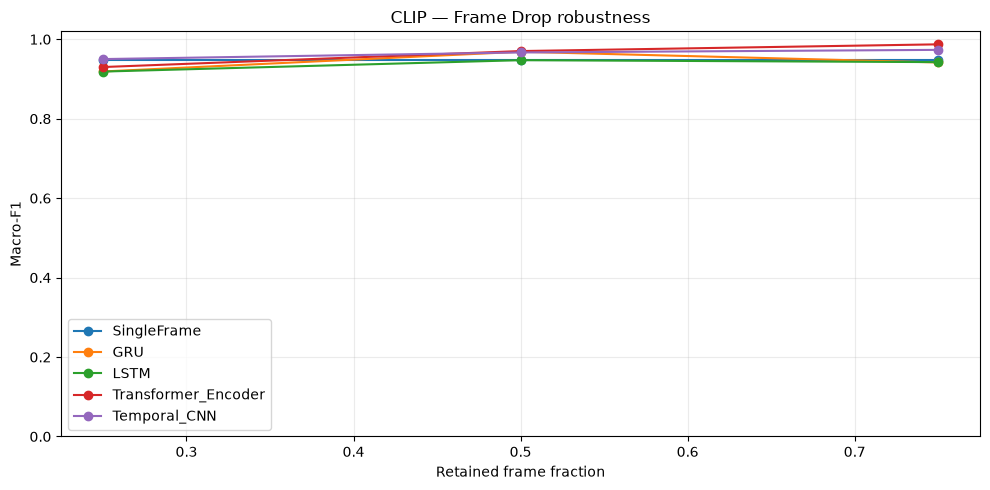

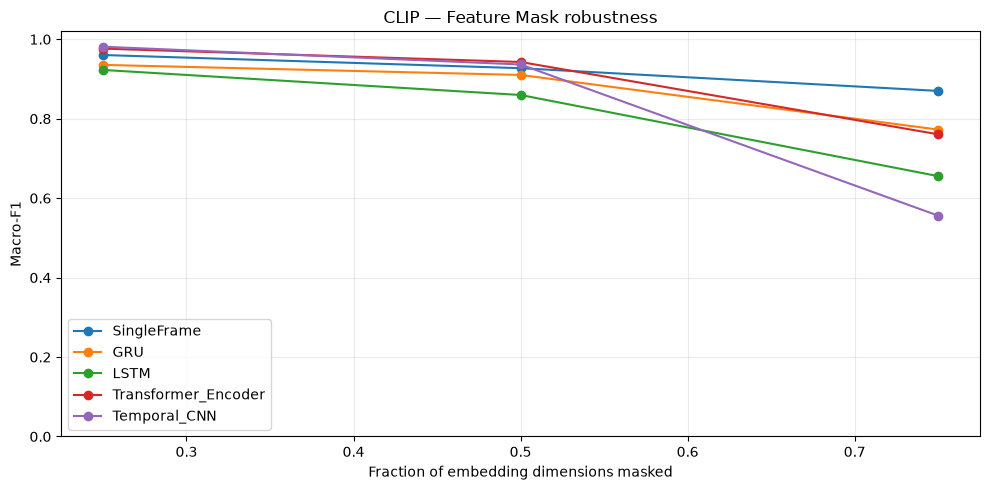

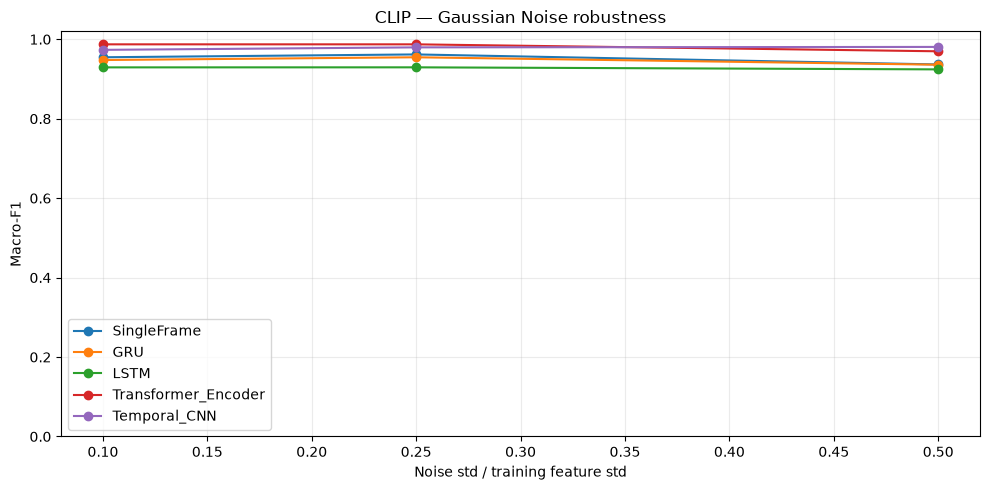

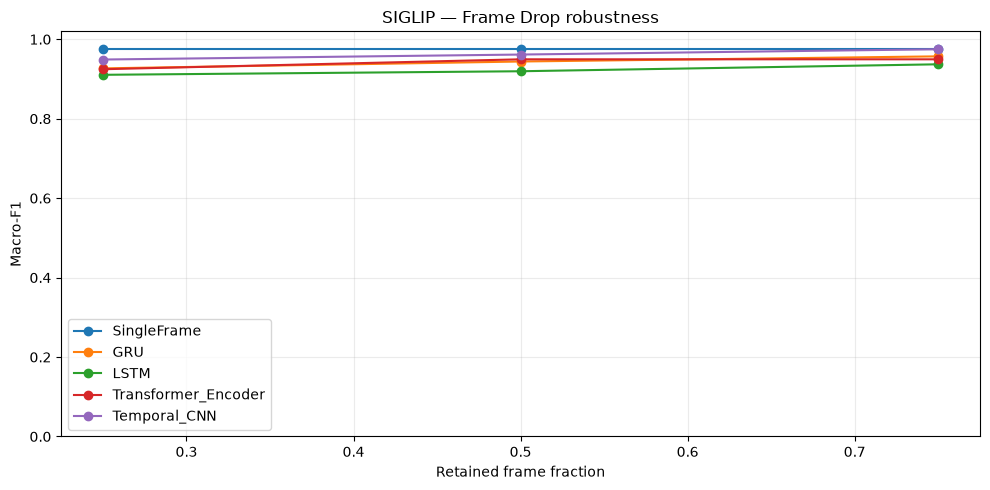

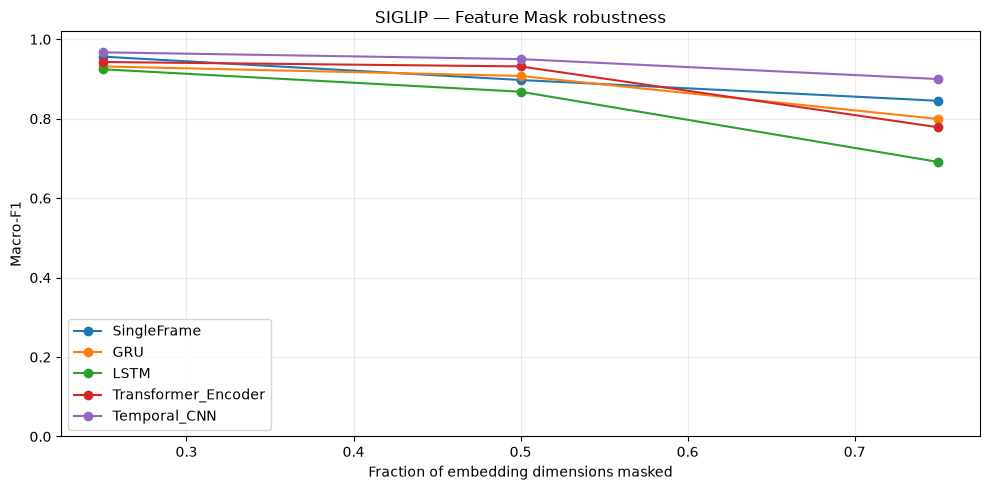

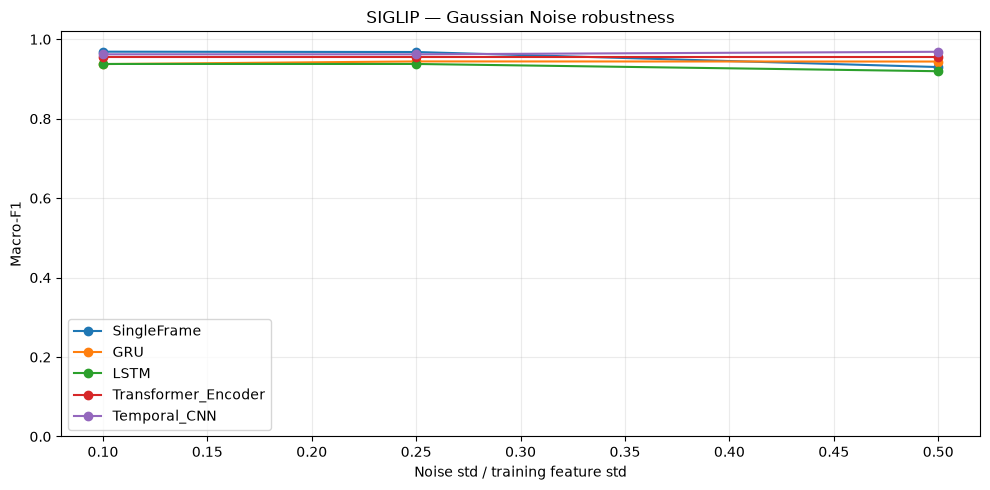

,encoder,model,condition,severity,macro_f1,clean_macro_f1,macro_f1_degradation_pp
1,clip,GRU,clean,0.00,0.947762,0.947762,0.000000
2,clip,LSTM,clean,0.00,0.942489,0.942489,0.000000
0,clip,SingleFrame,clean,0.00,0.947886,0.947886,0.000000
4,clip,Temporal_CNN,clean,0.00,0.973347,0.973347,0.000000
3,clip,Transformer_Encoder,clean,0.00,0.987273,0.987273,0.000000
...,...,...,...,...,...,...,...
94,siglip,Temporal_CNN,gaussian_noise,0.25,0.962140,0.962140,0.000000
99,siglip,Temporal_CNN,gaussian_noise,0.50,0.968535,0.962140,-0.639552
88,siglip,Transformer_Encoder,gaussian_noise,0.10,0.956124,0.956124,0.000000
93,siglip,Transformer_Encoder,gaussian_noise,0.25,0.956124,0.956124,0.000000


In [14]:
clean_ref = corruption_df[corruption_df["condition"] == "clean"][
    ["encoder", "model", "macro_f1"]
].rename(columns={"macro_f1": "clean_macro_f1"})
corruption_delta = corruption_df.merge(clean_ref, on=["encoder", "model"], how="left")
corruption_delta["macro_f1_change_pp"] = (
    corruption_delta["macro_f1"] - corruption_delta["clean_macro_f1"]
) * 100
corruption_delta["macro_f1_degradation_pp"] = (
    corruption_delta["clean_macro_f1"] - corruption_delta["macro_f1"]
) * 100
corruption_delta.to_csv(
    CORRUPTION_ROOT / "corruption_degradation_vs_clean.csv", index=False
)

for enc in ENCODERS:
    for condition in ["frame_drop", "feature_mask", "gaussian_noise"]:
        part = corruption_delta[
            (corruption_delta["encoder"] == enc) &
            (corruption_delta["condition"] == condition)
        ]
        fig, ax = plt.subplots(figsize=(10, 5))
        for model_name in corruption_models:
            p = part[part["model"] == model_name].sort_values("severity")
            ax.plot(p["severity"], p["macro_f1"], marker="o", label=model_name)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel({
            "frame_drop": "Retained frame fraction",
            "feature_mask": "Fraction of embedding dimensions masked",
            "gaussian_noise": "Noise std / training feature std",
        }[condition])
        ax.set_ylabel("Macro-F1")
        ax.set_title(f"{enc.upper()} — {condition.replace('_', ' ').title()} robustness")
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        fig.savefig(CORRUPTION_ROOT / f"{enc}_{condition}_robustness.png", dpi=160)
        plt.show()
        plt.close(fig)

display(corruption_delta.sort_values(
    ["encoder", "condition", "model", "severity"]
)[["encoder", "model", "condition", "severity",
   "macro_f1", "clean_macro_f1", "macro_f1_degradation_pp"]])


## 14. Compact comparison: single-frame vs validation-selected temporal model

This table isolates the main assignment comparison for each encoder. The temporal architecture is selected using its saved validation macro-F1, then evaluated on the held-out test set. This avoids choosing the winner based on test-set performance.

The table includes clean performance, temporal-order sensitivity, and corruption degradation.

In [ ]:
main_comparison_rows = []
for enc in ENCODERS:
    best_temporal = best_temporal_by_encoder[enc]
    for model_name in ["SingleFrame", best_temporal]:
        clean = corruption_df[
            (corruption_df["encoder"] == enc) &
            (corruption_df["model"] == model_name) &
            (corruption_df["condition"] == "clean")
        ].iloc[0]
        row = {
            "encoder": enc, "model": model_name,
            "clean_accuracy": clean["accuracy"],
            "clean_macro_f1": clean["macro_f1"],
        }
        for condition in ["frame_drop", "feature_mask", "gaussian_noise"]:
            sub = corruption_df[
                (corruption_df["encoder"] == enc) &
                (corruption_df["model"] == model_name) &
                (corruption_df["condition"] == condition)
            ]
            row[f"{condition}_worst_macro_f1"] = float(sub["macro_f1"].min())
        if model_name in TEMPORAL_MODELS:
            op = order_summary[
                (order_summary["encoder"] == enc) &
                (order_summary["model"] == model_name)
            ].set_index("condition")
            row["chronological_macro_f1"] = op.loc["chronological", "macro_f1_mean"]
            row["shuffled_macro_f1_mean"] = op.loc["shuffled", "macro_f1_mean"]
            row["shuffled_macro_f1_std"] = op.loc["shuffled", "macro_f1_std"]
            row["reversed_macro_f1"] = op.loc["reversed", "macro_f1_mean"]
        else:
            row["chronological_macro_f1"] = np.nan
            row["shuffled_macro_f1_mean"] = np.nan
            row["shuffled_macro_f1_std"] = np.nan
            row["reversed_macro_f1"] = np.nan
        main_comparison_rows.append(row)

main_comparison = pd.DataFrame(main_comparison_rows)
main_comparison.to_csv(SUMMARY_ROOT / "single_frame_vs_best_temporal.csv", index=False)
display(main_comparison)


,encoder,model,clean_accuracy,clean_macro_f1,frame_drop_worst_macro_f1,feature_mask_worst_macro_f1,gaussian_noise_worst_macro_f1,chronological_macro_f1,shuffled_macro_f1_mean,shuffled_macro_f1_std,reversed_macro_f1
0,clip,SingleFrame,0.944056,0.947886,0.947886,0.869970,0.936627,NaN,NaN,NaN,NaN
1,clip,Transformer_Encoder,0.986014,0.987273,0.930108,0.760741,0.969745,0.987273,0.980487,0.005203,0.981099
2,siglip,SingleFrame,0.972028,0.974602,0.974602,0.845138,0.930107,NaN,NaN,NaN,NaN
3,siglip,Transformer_Encoder,0.951049,0.956124,0.924570,0.778504,0.956124,0.956124,0.953432,0.003382,0.949567


## 15. Save experiment provenance and interpretation checklist

The provenance file records the input artifacts, split, checkpoints, corruption settings, random seeds and key methodological choices. Review the checklist after execution and write conclusions only from the generated CSVs/plots.

In [16]:
provenance = {
    "project": "Temporal Vision — Temporal Evaluation",
    "stage": 5,
    "dataset": "HMDB51 local subset",
    "project_root": str(PROJECT_ROOT),
    "output_root": str(OUTPUT_ROOT),
    "embedding_root": str(EMBEDDINGS_ROOT),
    "stage4_root": str(STAGE4_ROOT),
    "device": str(DEVICE),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "seed": SEED,
    "test_video_count": len(TEST_IDS),
    "classes": LABELS,
    "split_source": str(split_path),
    "encoders": ENCODERS,
    "loaded_checkpoints": CHECKPOINT_METADATA,
    "experiments": {
        "progressive_observation": {
            "method": "uniformly sample k observations across the full temporal span; k=1 uses middle frame",
            "k_values": list(range(1, max_frames + 1)),
            "models": ALL_MODELS,
            "retrained": False,
        },
        "temporal_order": {
            "conditions": ["chronological", "reversed", "shuffled"],
            "random_shuffle_repeats": N_SHUFFLE_REPEATS,
            "seed": SEED,
        },
        "observation_corruption": {
            "conditions": {
                "frame_drop_retained_fraction": DROP_RETAIN_RATES,
                "feature_mask_fraction": MASK_RATES,
                "gaussian_noise_std_relative_to_train_feature_std": NOISE_SCALES,
            },
            "noise_scale_estimated_from_train_videos_only": True,
            "pixel_blur_or_pixel_occlusion_applied": False,
            "reason": "Only precomputed frame embeddings are available in this notebook.",
        },
    },
    "limitations": [
        "Models were trained on full sequences; progressive observation evaluates reduced inputs without retraining.",
        "Embedding-space masking/noise is not equivalent to pixel-space blur or partial image occlusion.",
        "Single-frame baseline cannot be meaningfully degraded by dropping additional frames.",
        "Results are limited to the current HMDB51 subset and saved test split.",
        "Best temporal model selection based on stage-4 test metrics is descriptive, not confirmatory.",
    ],
}
(OUTPUT_ROOT / "experiment_provenance.json").write_text(json.dumps(provenance, indent=2))
print("Saved provenance:", OUTPUT_ROOT / "experiment_provenance.json")
print("\nOutput files:")
for p in sorted(OUTPUT_ROOT.rglob("*")):
    if p.is_file():
        print(" -", p.relative_to(OUTPUT_ROOT))


Saved provenance: /Users/vanshikaarora/Desktop/Tracking/Temporal-Evaluation/experiment_provenance.json

Output files:
 - Observation_Corruption/clip_GRU_feature_mask_0p25_predictions.csv
 - Observation_Corruption/clip_GRU_feature_mask_0p5_predictions.csv
 - Observation_Corruption/clip_GRU_feature_mask_0p75_predictions.csv
 - Observation_Corruption/clip_GRU_frame_drop_0p25_predictions.csv
 - Observation_Corruption/clip_GRU_frame_drop_0p5_predictions.csv
 - Observation_Corruption/clip_GRU_frame_drop_0p75_predictions.csv
 - Observation_Corruption/clip_GRU_gaussian_noise_0p1_predictions.csv
 - Observation_Corruption/clip_GRU_gaussian_noise_0p25_predictions.csv
 - Observation_Corruption/clip_GRU_gaussian_noise_0p5_predictions.csv
 - Observation_Corruption/clip_LSTM_feature_mask_0p25_predictions.csv
 - Observation_Corruption/clip_LSTM_feature_mask_0p5_predictions.csv
 - Observation_Corruption/clip_LSTM_feature_mask_0p75_predictions.csv
 - Observation_Corruption/clip_LSTM_frame_drop_0p25_pred

## 16. Final research questions

After the notebook finishes, use the saved outputs to answer:

1. Does performance improve as more observations become available, and does it saturate?
2. Does the temporal model outperform the single-frame baseline at each observation budget?
3. Does reversing or shuffling the sequence hurt performance consistently?
4. How variable is shuffled-order performance across 20 permutations?
5. Which model is most robust to missing frames?
6. Which model is most robust to feature masking and additive feature noise?
7. Does the best temporal model retain an advantage over the single-frame baseline under corruption?
8. Do CLIP and SigLIP respond differently to observation count, order and corruption?

### Interpretation guardrails
- Do not equate multi-frame aggregation with learning motion.
- Do not describe embedding-space masking/noise as pixel blur or image occlusion.
- Do not claim statistical significance from one held-out split.
- A model that improves after shuffling may be using the set of observations more than their chronology.
- If the progressive curve falls at low `k`, remember these checkpoints were trained on full sequences and were not fine-tuned for low-observation inference.

**Expected output root:** `Tracking/Temporal-Evaluation/`

The notebook is designed to be run after Notebook 03. It reuses its checkpoints and split and does not repeat model training.
